In [1]:
%%time
%pip install -q numpy==1.26.4 pandas matplotlib seaborn scikit-learn nltk
%pip install torch==2.2.2+cpu torchvision==0.17.2+cpu torchtext==0.17.2+cpu  \
    --index-url https://download.pytorch.org/whl/cpu

Note: you may need to restart the kernel to use updated packages.
Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.
CPU times: total: 46.9 ms
Wall time: 4.48 s


In [2]:
%%capture
import warnings
from tqdm import tqdm

warnings.simplefilter('ignore')
import time
from collections import OrderedDict

import re

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import string
import time
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator
from nltk.tokenize import word_tokenize

from sklearn.manifold import TSNE

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

In [3]:
%%capture
import warnings
from tqdm import tqdm

warnings.simplefilter('ignore')
import time
from collections import OrderedDict

import re

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import string
import time
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator
from nltk.tokenize import word_tokenize

from sklearn.manifold import TSNE

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

In [4]:
song= """We are no strangers to love
You know the rules and so do I
A full commitments what Im thinking of
You wouldnt get this from any other guy
I just wanna tell you how Im feeling
Gotta make you understand
Never gonna give you up
Never gonna let you down
Never gonna run around and desert you
Never gonna make you cry
Never gonna say goodbye
Never gonna tell a lie and hurt you
Weve known each other for so long
Your hearts been aching but youre too shy to say it
Inside we both know whats been going on
We know the game and were gonna play it
And if you ask me how Im feeling
Dont tell me youre too blind to see
Never gonna give you up
Never gonna let you down
Never gonna run around and desert you
Never gonna make you cry
Never gonna say goodbye
Never gonna tell a lie and hurt you
Never gonna give you up
Never gonna let you down
Never gonna run around and desert you
Never gonna make you cry
Never gonna say goodbye
Never gonna tell a lie and hurt you
Weve known each other for so long
Your hearts been aching but youre too shy to say it
Inside we both know whats been going on
We know the game and were gonna play it
I just wanna tell you how Im feeling
Gotta make you understand
Never gonna give you up
Never gonna let you down
Never gonna run around and desert you
Never gonna make you cry
Never gonna say goodbye
Never gonna tell a lie and hurt you
Never gonna give you up
Never gonna let you down
Never gonna run around and desert you
Never gonna make you cry
Never gonna say goodbye
Never gonna tell a lie and hurt you
Never gonna give you up
Never gonna let you down
Never gonna run around and desert you
Never gonna make you cry
Never gonna say goodbye
Never gonna tell a lie and hurt you"""

In [5]:
tokenizer = get_tokenizer("basic_english")
tokens=tokenizer(song)

In [6]:
def preprocess_string(s):
  

    # Remove all non-word characters (everything except letters and numbers)
    # \w matches any word character (letters, numbers, and underscores)
    # \s matches any whitespace characters
    # ^ inside [] negates the selection, so [^\w\s] matches anything that's NOT a word character or whitespace.
    s = re.sub(r"[^\w\s]", '', s)

    # Remove all whitespace characters (spaces, tabs, newlines)
    # \s+ matches one or more whitespace characters.
    s = re.sub(r"\s+", '', s)

    # Remove all digits (0-9)
    # \d matches any digit character.
    s = re.sub(r"\d", '', s)

    return s

In [7]:
def preprocess(words):


    # Tokenize the input text into words
    tokens = word_tokenize(words)

    # Apply preprocessing to each token (removes unwanted characters)
    tokens = [preprocess_string(w) for w in tokens]

    # Convert tokens to lowercase and remove empty strings or punctuation
    return [w.lower() for w in tokens if len(w) != 0 and w not in string.punctuation]

# Example usage:
tokens = preprocess(song)  # Preprocess the text in 'song'

In [8]:
def tokenizetext(song):
  

    # Tokenize the text
    # Split the input text into words and apply the tokenizer function to each word.
    # The 'map' function ensures that each word is tokenized properly.
    tokenized_song = map(tokenizer, song.split())

    # Build vocabulary from tokenized text
    # The function `build_vocab_from_iterator` constructs a vocabulary by iterating 
    # over the tokenized words. The special token "<unk>" is added to handle words 
    # that are not present in the vocabulary.
    vocab = build_vocab_from_iterator(tokenized_song, specials=["<unk>"])

    # Set the default index for unknown words
    # The default index is set to the index of "<unk>" so that any word not found 
    # in the vocabulary is mapped to this token, preventing errors during lookup.
    vocab.set_default_index(vocab["<unk>"])

    return vocab


In [9]:
vocab=tokenizetext(song)
vocab(tokens[0:10])

[21, 58, 70, 74, 25, 69, 2, 20, 31, 72]

In [10]:
tokens[0:10]

['we', 'are', 'no', 'strangers', 'to', 'love', 'you', 'know', 'the', 'rules']

In [11]:
text_pipeline = lambda x: vocab(tokenizer(x))
text_pipeline(song)[0:10]

[21, 58, 70, 74, 25, 69, 2, 20, 31, 72]

In [12]:
index_to_token = vocab.get_itos()
index_to_token[58]

'are'

In [13]:
def genembedding(vocab):


    # Define the embedding dimension (size of word vectors)
    embedding_dim = 20  # Each word will be represented as a 20-dimensional vector

    # Get the vocabulary size (number of unique words in the vocabulary)
    vocab_size = len(vocab)

    # Create an embedding layer
    # The nn.Embedding module maps word indices to dense vector representations.
    # It takes vocab_size as the number of words and embedding_dim as the vector size.
    embeddings = nn.Embedding(vocab_size, embedding_dim)

    return embeddings

In [14]:
embeddings=genembedding(vocab)
for n in range(2): 
    embedding=embeddings(torch.tensor(n))
    print("word",index_to_token[n])
    print("index",n)
    print( "embedding", embedding)
    print("embedding shape", embedding.shape)

word <unk>
index 0
embedding tensor([ 0.9613,  1.3164, -0.7093,  0.6646, -0.7813,  0.5690,  0.1101,  1.2711,
        -0.4589,  1.8428, -1.8156, -0.8037,  0.8351, -0.8453,  0.1645,  0.7390,
        -0.2856,  0.9066, -0.6228,  1.3145], grad_fn=<EmbeddingBackward0>)
embedding shape torch.Size([20])
word gonna
index 1
embedding tensor([ 0.1391, -1.6270, -1.4323, -0.2062,  0.0956, -1.2506, -0.1703,  0.6977,
         0.4549,  1.9158,  0.5062, -0.3164, -1.6904,  0.1739,  0.2326, -0.9162,
        -0.4374,  0.2278,  0.4170,  0.9951], grad_fn=<EmbeddingBackward0>)
embedding shape torch.Size([20])


In [15]:
# Define the context size for generating n-grams
CONTEXT_SIZE = 2  # The number of previous words used to predict the next word

def genngrams(tokens):


    # Generate n-grams
    # Iterate through the tokens starting from index CONTEXT_SIZE to the end
    # For each token at position 'i', extract the previous CONTEXT_SIZE words as context
    ngrams = [
        (
            [tokens[i - j - 1] for j in range(CONTEXT_SIZE)],  # Context words (previous words)
            tokens[i]  # Target word (the word to predict)
        )
        for i in range(CONTEXT_SIZE, len(tokens))
    ]

    return ngrams


In [16]:
ngrams=genngrams(tokens)
context, target=ngrams[0]
print("context",context,"target",target)
print("context index",vocab(context),"target index",vocab([target]))

context ['are', 'we'] target no
context index [58, 21] target index [70]


In [17]:
embedding_dim=20
linear = nn.Linear(embedding_dim*CONTEXT_SIZE,128)

In [18]:
embeddings=genembedding(vocab)
my_embeddings=embeddings(torch.tensor(vocab(context)))
my_embeddings.shape

torch.Size([2, 20])

In [19]:
my_embeddings=my_embeddings.reshape(1,-1)
my_embeddings.shape

torch.Size([1, 40])

In [20]:
linear(my_embeddings)

tensor([[ 6.7650e-01,  1.6528e-02, -5.5250e-01, -1.1637e+00, -1.9662e-01,
          2.2991e-01, -1.0511e-01,  3.3208e-01,  1.7804e-01, -3.9897e-01,
         -1.0129e+00, -5.3415e-01,  1.0893e-01,  4.9502e-02, -8.8731e-01,
          1.2563e-01,  4.1839e-01, -3.6537e-02,  5.0848e-02,  4.6590e-02,
          9.2688e-01, -1.8766e-01,  4.0036e-02,  4.6076e-01, -4.6004e-01,
         -6.7089e-01,  4.4099e-01, -6.5087e-01,  1.9864e-01,  8.9762e-01,
          5.3881e-01,  1.8701e-02, -2.1801e-01, -4.1223e-02,  3.1723e-01,
         -5.3811e-01, -6.6546e-02, -8.8367e-01,  9.0591e-02,  7.3455e-01,
         -2.7096e-01, -4.3015e-01, -2.8616e-01, -1.4530e-01,  3.6269e-01,
         -1.0382e+00, -1.5859e+00,  3.8697e-01, -1.7425e-01,  1.1276e-01,
          2.2468e-01, -3.2540e-01,  6.5762e-02,  7.6006e-01, -2.9595e-01,
         -1.4773e-01,  5.4003e-01,  2.9935e-01,  1.2818e+00, -5.6541e-01,
          1.3724e-01, -1.1567e-01, -7.5448e-03,  8.4726e-01,  4.2360e-01,
          4.3050e-01,  8.0245e-01,  5.

In [21]:
from torch.utils.data import DataLoader  # Importing DataLoader for batch processing
import torch  # Importing PyTorch

# Set the device to GPU if available; otherwise, use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define hyperparameters
CONTEXT_SIZE = 3   # Number of previous words used as context for prediction
BATCH_SIZE = 10    # Number of samples per training batch
EMBEDDING_DIM = 10 # Dimension of word embeddings

def collate_batch(batch):
    """
    Processes a batch of text data into input (context) and output (target) tensors
    for training a language model.

    The function extracts:
    - `context`: A list of word indices representing the context words for each target word.
    - `target`: A list of word indices representing the target word to predict.

    Parameters:
    batch (list): A list of tokenized words (strings).

    Returns:
    tuple: Two PyTorch tensors: (context_tensor, target_tensor)
           - context_tensor: Tensor of shape (batch_size - CONTEXT_SIZE, CONTEXT_SIZE),
             containing the word indices of context words.
           - target_tensor: Tensor of shape (batch_size - CONTEXT_SIZE,),
             containing the word indices of target words.
    """

    batch_size = len(batch)  # Get the size of the batch
    context, target = [], [] # Initialize lists for context and target words

    # Loop through the batch, ensuring enough previous words exist for context
    for i in range(CONTEXT_SIZE, batch_size):
        # Convert the target word to its index using the vocabulary
        target.append(vocab([batch[i]]))

        # Convert the previous CONTEXT_SIZE words to indices using the vocabulary
        context.append(vocab([batch[i - j - 1] for j in range(CONTEXT_SIZE)]))

    # Convert lists to PyTorch tensors and move them to the appropriate device (CPU/GPU)
    return torch.tensor(context).to(device), torch.tensor(target).to(device).reshape(-1)


In [22]:
Padding=BATCH_SIZE-len(tokens)%BATCH_SIZE
tokens_pad=tokens+tokens[0:Padding]


In [23]:
dataloader = DataLoader(
     tokens_pad, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch
)

In [24]:
class NGramLanguageModeler(nn.Module):
 

    def __init__(self, vocab_size, embedding_dim, context_size):
        super(NGramLanguageModeler, self).__init__()

        # Store context size and embedding dimension
        self.context_size = context_size
        self.embedding_dim = embedding_dim

        # Embedding layer: Maps word indices to dense vectors
        self.embeddings = nn.Embedding(vocab_size, embedding_dim)

        # Fully connected hidden layer: Maps the concatenated embeddings to a 128-dimensional space
        self.linear1 = nn.Linear(context_size * embedding_dim, 128)

        # Output layer: Maps the hidden layer output to vocabulary size (probability distribution over words)
        self.linear2 = nn.Linear(128, vocab_size)

    def forward(self, inputs):
        """
        Forward pass of the model.

        Parameters:
        inputs (Tensor): A tensor of shape (batch_size, context_size) containing word indices.

        Returns:
        Tensor: A tensor of shape (batch_size, vocab_size) representing predicted probabilities for the next word.
        """

        # Convert input word indices into dense vectors using the embedding layer
        embeds = self.embeddings(inputs)  # Shape: (batch_size, context_size, embedding_dim)

        # Reshape the embeddings into a single vector per input sample
        embeds = torch.reshape(embeds, (-1, self.context_size * self.embedding_dim))  
        # New shape: (batch_size, context_size * embedding_dim)

        # Apply first fully connected layer with ReLU activation
        out = F.relu(self.linear1(embeds))  # Shape: (batch_size, 128)

        # Apply second fully connected layer to generate vocabulary-size logits
        out = self.linear2(out)  # Shape: (batch_size, vocab_size)

        return out


In [25]:
model = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)

In [26]:
context, target=next(iter(dataloader))
print(context, target)
out=model(context)

tensor([[70, 58, 21],
        [74, 70, 58],
        [25, 74, 70],
        [69, 25, 74],
        [ 2, 69, 25],
        [20,  2, 69],
        [31, 20,  2]]) tensor([74, 25, 69,  2, 20, 31, 72])


In [27]:
out.shape

torch.Size([7, 79])

In [28]:
predicted_index =torch.argmax(out,1)
predicted_index

tensor([23, 21, 26, 70,  6, 41, 77])

In [29]:
[index_to_token[i.item()] for i in  predicted_index]

['im', 'we', 'feeling', 'no', 'make', 'gotta', 'what']

In [30]:
def write_song(model, my_song, number_of_words=100):
   

    # Get the mapping from index to word for decoding predictions
    index_to_token = vocab.get_itos()

    # Loop to generate the desired number of words
    for i in range(number_of_words):

        with torch.no_grad():  # Disable gradient computation for inference
            
            # Prepare the input context by extracting the last CONTEXT_SIZE words from tokens
            context = torch.tensor(
                vocab([tokens[i - j - 1] for j in range(CONTEXT_SIZE)])
            ).to(device)  # Move to CPU/GPU as required
            
            # Predict the next word by selecting the word with the highest probability
            word_idx = torch.argmax(model(context))  # Get index of the most likely next word
            
            # Append the predicted word to the generated text
            my_song += " " + index_to_token[word_idx.detach().item()]

    return my_song  # Return the generated lyrics


In [31]:
def pickrandomline(song):

    
    # Split the song into individual lines
    lines = song.split("\n")  
    
    # Randomly select a line and remove leading/trailing whitespace
    selected_line = random.choice(lines).strip()
    
    return selected_line  # Return the randomly selected line

# Example usage:
selected_line = pickrandomline(song)  # Pick a random line from the song

# Generate a new song starting with the selected line
generated_song = write_song(model, selected_line)

# Print the generated lyrics
print(generated_song)


We know the game and were gonna play it aching get full im we feeling no make gotta what goodbye the make hearts gotta hurt hurt hurt full hurt it gotta cry full full the hurt how never just get no full full hearts hurt hurt run get no no full cry full hurt it no full hurt get hurt it no hearts hurt get hurt it no gotta get the never cry hurt run no full cry hurt hurt full no get the hurt full no hearts and hurt full hurt aching get goodbye never gotta hurt full get make understand cry hurt how gotta gotta hurt the


In [32]:
#TRAINGING

criterion = torch.nn.CrossEntropyLoss()

In [33]:
def train(dataloader, model,song,number_of_epochs=100, show=10):


    MY_LOSS = []  # List to store loss values for each epoch

    # Iterate over the specified number of epochs
    for epoch in tqdm(range(number_of_epochs)):
        total_loss = 0  # Initialize total loss for the current epoch
        my_song = ""    # Initialize a string to store the generated song

        # Iterate over batches in the dataloader
        for context, target in dataloader:
            model.zero_grad()          # Zero the gradients to avoid accumulation
            predicted = model(context)  # Forward pass through the model to get predictions
            loss = criterion(predicted, target.reshape(-1))  # Calculate the loss
            total_loss += loss.item()   # Accumulate the loss

            loss.backward()    # Backpropagation to compute gradients
            optimizer.step()   # Update model parameters using the optimizer

        # Display progress and generate song at specified intervals
        if epoch % show == 0:
            selected_line=pickrandomline(song)
            my_song += write_song(model, selected_line)    # Generate song using the model

            print("Generated Song:")
            print("\n")
            print(my_song)

        MY_LOSS.append(total_loss/len(dataloader))  # Append the total loss for the epoch to MY_LOSS list

    return MY_LOSS  # Return the list of  mean loss values for each epoch

In [34]:
my_loss_list=[]

In [35]:
# Define the context size for the n-gram model
CONTEXT_SIZE = 2

# Create an instance of the NGramLanguageModeler class with specified parameters
model_2 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)

# Define the optimizer for training the model, using stochastic gradient descent (SGD)
optimizer = optim.SGD(model_2.parameters(), lr=0.01)

# Set up a learning rate scheduler using StepLR to adjust the learning rate during training
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1.0, gamma=0.1)

In [36]:
my_loss=train(dataloader,model_2,song)

  7%|▋         | 7/100 [00:00<00:02, 32.35it/s]

Generated Song:


Never gonna run around and desert you never <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> if on <unk> <unk> <unk> on <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> the <unk> on <unk> <unk> <unk> i <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> to <unk> <unk> <unk> never <unk> <unk> <unk> <unk> <unk> rules <unk> <unk> <unk> <unk> <unk> <unk> <unk> rules <unk> <unk>


 15%|█▌        | 15/100 [00:00<00:02, 35.31it/s]

Generated Song:


We know the game and were gonna play it never never you you never <unk> you <unk> never <unk> you <unk> you you you you never never never you never you <unk> never you you <unk> you never never you you <unk> you you never <unk> you never <unk> you you never <unk> <unk> <unk> you you never never <unk> <unk> you you <unk> never <unk> <unk> you you you <unk> you never <unk> <unk> you you never never <unk> <unk> you you you <unk> <unk> you you never <unk> you you never never never <unk> never never never never never never you never you you you <unk> you


 28%|██▊       | 28/100 [00:00<00:01, 36.61it/s]

...

 85%|████████▌ | 85/100 [00:02<00:00, 32.16it/s]

Generated Song:


Never gonna run around and desert you never know no strangers to <unk> you never the game you desert you i a to commitments and im feeling been but down never to you hurt you how i a to <unk> tell you how im feeling <unk> <unk> tell you understand never <unk> <unk> tell you we never <unk> <unk> tell you down never <unk> <unk> tell around and desert you never <unk> <unk> tell you understand never <unk> <unk> tell goodbye never <unk> <unk> tell you how and hurt you never known each other for never been we hearts been aching but youre too shy to say


 94%|█████████▍| 94/100 [00:02<00:00, 34.34it/s]

Generated Song:


We are no strangers to love never know no strangers to love you know the game you desert you i a full commitments and im feeling been but wouldnt never to you hurt you how i a to <unk> tell you how im feeling <unk> <unk> tell you understand never <unk> <unk> tell you up never <unk> <unk> tell you down never <unk> <unk> tell around and desert you never <unk> <unk> tell you understand never <unk> <unk> tell goodbye never <unk> <unk> tell you how and hurt you never known each other for never been your hearts been aching but youre too shy to say


100%|██████████| 100/100 [00:02<00:00, 34.16it/s]


In [37]:
save_path = '2gram.pth'
torch.save(model_2.state_dict(), save_path)
my_loss_list.append(my_loss)

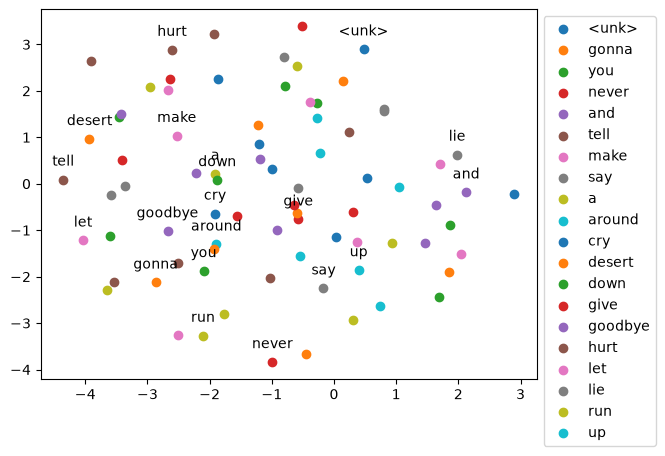

In [38]:
X = model_2.embeddings.weight.cpu().detach().numpy()
tsne = TSNE(n_components=2, random_state=42)
X_2d = tsne.fit_transform(X)

labels = []

for j in range(len(X_2d)):
    if j < 20:
        plt.scatter(X_2d[j, 0], X_2d[j, 1], label=index_to_token[j])
        labels.append(index_to_token[j])
        # Add words as annotations
        plt.annotate(index_to_token[j],
                     (X_2d[j, 0], X_2d[j, 1]),
                     textcoords="offset points",
                     xytext=(0, 10),
                     ha='center')
    else:
        plt.scatter(X_2d[j, 0], X_2d[j, 1])

plt.legend(labels, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

In [39]:
import numpy as np
print(np.__version__)

1.26.4


In [40]:
CONTEXT_SIZE=4
model_4 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)
optimizer = optim.SGD(model_4.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 1.0, gamma=0.1)
my_loss=train(dataloader,model_4,song)

save_path = '4gram.pth'
torch.save(model_4.state_dict(), save_path)

my_loss_list.append(my_loss)

  4%|▍         | 4/100 [00:00<00:02, 32.91it/s]

Generated Song:


A full commitments what Im thinking of never <unk> <unk> never <unk> you <unk> <unk> <unk> <unk> <unk> <unk> <unk> goodbye <unk> never a say a never <unk> known <unk> <unk> just <unk> <unk> <unk> are know <unk> <unk> <unk> <unk> you get <unk> understand <unk> <unk> <unk> goodbye <unk> never <unk> <unk> <unk> you get <unk> get <unk> <unk> you get <unk> <unk> <unk> <unk> you <unk> gonna you <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> you get get never <unk> never <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> get <unk> <unk> get <unk> tell <unk> im


 16%|█▌        | 16/100 [00:00<00:02, 34.49it/s]

Generated Song:


Never gonna say goodbye never you you never never you never <unk> you you <unk> <unk> you never you never you you you you <unk> you never <unk> never <unk> <unk> you you <unk> <unk> <unk> <unk> tell you down you you never <unk> <unk> you never never <unk> <unk> give you never never <unk> <unk> let you down never <unk> <unk> tell you never never you never <unk> <unk> make you never never <unk> <unk> say you never <unk> <unk> tell you down never never you never <unk> <unk> never <unk> <unk> <unk> <unk> you <unk> <unk> you you say you never never


 25%|██▌       | 25/100 [00:00<00:02, 36.60it/s]

...

 84%|████████▍ | 84/100 [00:02<00:00, 34.97it/s]

Generated Song:


Never gonna make you cry never are no strangers to love you know the rules <unk> were you how a full commitments what im thinking each say we are this from any other guy i <unk> tell <unk> tell you how im feeling <unk> <unk> give you understand never <unk> <unk> give you up never how <unk> let you down never <unk> <unk> run around lie im you never <unk> <unk> make you understand never <unk> <unk> say goodbye never <unk> <unk> tell you lie im feeling you never known each other for so long to a been aching but youre too shy to say


 96%|█████████▌| 96/100 [00:02<00:00, 33.13it/s]

Generated Song:


Never gonna run around and desert you never are no strangers to love you know the rules <unk> were you how a full commitments what im thinking each say we are this from any other guy i <unk> tell <unk> tell you how im feeling <unk> <unk> give you understand never <unk> <unk> give you up never how <unk> let you down never <unk> <unk> run around lie im you never <unk> <unk> make you understand never <unk> <unk> say goodbye never <unk> <unk> tell a lie im feeling you never known each other for so long to a been aching but youre too shy to say


100%|██████████| 100/100 [00:02<00:00, 35.87it/s]


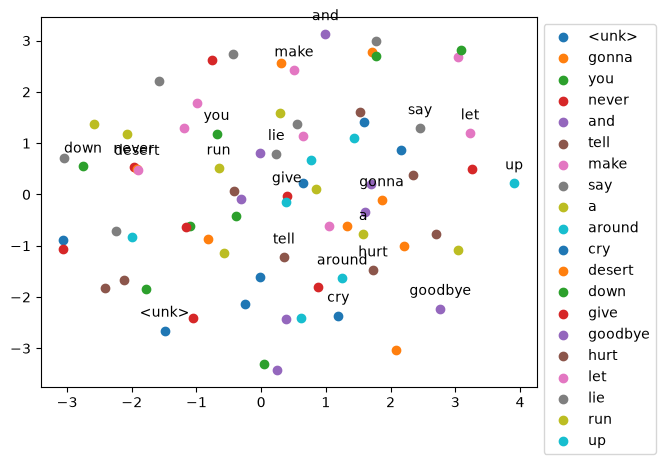

In [41]:
X = model_4.embeddings.weight.cpu().detach().numpy()
tsne = TSNE(n_components=2, random_state=42)
X_2d = tsne.fit_transform(X)

labels = []

for j in range(len(X_2d)):
    if j < 20:
        plt.scatter(X_2d[j, 0], X_2d[j, 1], label=index_to_token[j])
        labels.append(index_to_token[j])
        # Add words as annotations
        plt.annotate(index_to_token[j],
                     (X_2d[j, 0], X_2d[j, 1]),
                     textcoords="offset points",
                     xytext=(0, 10),
                     ha='center')
    else:
        plt.scatter(X_2d[j, 0], X_2d[j, 1])

plt.legend(labels, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

In [42]:
CONTEXT_SIZE=8
model_8 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)
optimizer = optim.SGD(model_8.parameters(), lr=0.01)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 1.0, gamma=0.1)
my_loss=train(dataloader,model_8,song)

save_path = '8gram.pth'
torch.save(model_8.state_dict(), save_path)

my_loss_list.append(my_loss)

  4%|▍         | 4/100 [00:00<00:02, 33.06it/s]

Generated Song:


You wouldnt get this from any other guy <unk> <unk> <unk> <unk> <unk> commitments <unk> to no <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> inside rules <unk> <unk> <unk> you <unk> inside <unk> <unk> <unk> youre <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> you <unk> <unk> you <unk> to <unk> <unk> <unk> <unk> <unk> <unk> inside <unk> <unk>


 17%|█▋        | 17/100 [00:00<00:02, 38.67it/s]

Generated Song:


Never gonna give you up <unk> <unk> <unk> give to <unk> <unk> to the rules <unk> <unk> tell <unk> you make give you im <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> you <unk> you <unk> never tell <unk> give you im <unk> <unk> <unk> <unk> tell to never <unk> <unk> give you never never <unk> <unk> tell you im never <unk> <unk> give you never never <unk> tell <unk> <unk> make you cry never <unk> <unk> give you never <unk> <unk> tell give give give <unk> <unk> <unk> <unk> <unk> give you you long tell <unk> im <unk> <unk> tell tell shy to say


 26%|██▌       | 26/100 [00:00<00:01, 39.83it/s]

...

 86%|████████▌ | 86/100 [00:02<00:00, 41.04it/s]

Generated Song:


Never gonna give you up <unk> <unk> <unk> strangers to so long to the rules i <unk> tell guy i other give around im thinking <unk> <unk> <unk> <unk> going <unk> to you guy i around never give <unk> a up im feeling <unk> <unk> <unk> tell cry never <unk> <unk> give you up never <unk> <unk> give around up never <unk> <unk> run around never never <unk> tell <unk> <unk> make you cry never <unk> <unk> give you up never <unk> tell a lie never feeling <unk> <unk> <unk> <unk> other for so long i <unk> been <unk> <unk> we too shy to say


 96%|█████████▌| 96/100 [00:02<00:00, 39.94it/s]

Generated Song:


Never gonna say goodbye <unk> <unk> <unk> strangers to so long to the rules i <unk> tell guy i other give around im thinking <unk> <unk> <unk> <unk> going <unk> to you guy i around never give <unk> a up im feeling <unk> <unk> <unk> tell cry never <unk> <unk> give you up never <unk> <unk> give around up never <unk> <unk> run around never never <unk> tell <unk> <unk> make you cry never <unk> <unk> give you up never <unk> tell a lie never feeling <unk> <unk> <unk> <unk> other for so long i <unk> been <unk> <unk> we too shy to say


100%|██████████| 100/100 [00:02<00:00, 39.63it/s]


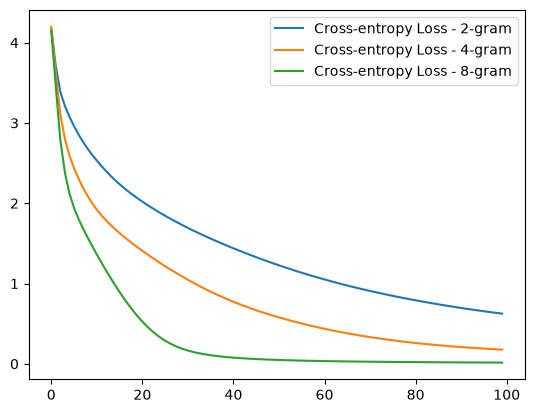

In [43]:
for (my_loss, model_name)in zip(my_loss_list,["2-gram","4-gram","8-gram"]):
    plt.plot(my_loss,label="Cross-entropy Loss - {}".format(model_name))
    plt.legend()

In [48]:
# Write your code here.
nursery_rhymes = """
Little Miss Muffet
Sat on a tuffet,
Eating her curds and whey;
Along came a spider
Who sat down beside her
And frightened Miss Muffet away.

Twinkle, twinkle, little star,
How I wonder what you are!
Up above the world so high,
Like a diamond in the sky.

Baa, baa, black sheep,
Have you any wool?
Yes sir, yes sir,
Three bags full.

Jack and Jill went up the hill
To fetch a pail of water.
Jack fell down and broke his crown,
And Jill came tumbling after.

Hickory dickory dock,
The mouse ran up the clock.
The clock struck one,
The mouse ran down,
Hickory dickory dock.

Humpty Dumpty sat on a wall,
Humpty Dumpty had a great fall.
All the king's horses and all the king's men
Couldn't put Humpty together again.

Mary had a little lamb,
Its fleece was white as snow;
And everywhere that Mary went,
The lamb was sure to go.

Old MacDonald had a farm,
E-I-E-I-O,
And on his farm he had a cow,
E-I-E-I-O.

Itsy Bitsy Spider climbed up the waterspout.
Down came the rain and washed the spider out.
Out came the sun and dried up all the rain,
And the Itsy Bitsy Spider climbed up the spout again.

The wheels on the bus go round and round,
Round and round,
Round and round.
The wheels on the bus go round and round,
All through the town.
"""

In [50]:
# Define the value of N for N-grams (context size)
N = 3

# Preprocess the text (e.g., nursery rhymes) to tokenize and clean it
tokens = preprocess(nursery_rhymes)  # Use the preprocess function to tokenize the text

# Generate N-grams using the `genngrams` function
ngrams = genngrams(tokens)  

# Extract the first context-target pair from the list of N-grams
context, target = ngrams[0] 

In [51]:

# Tokenize text and create vocabulary
vocab = tokenizetext(nursery_rhymes)  


# Define embedding dimensions and create layers
embedding_dim = 20  # Each word will be represented as a 20-dimensional vector
linear = nn.Linear(embedding_dim * CONTEXT_SIZE, 128)  


# Generate embeddings using the custom embedding function
embeddings = genembedding(vocab)  


# Convert context words into embeddings
my_embeddings = embeddings(torch.tensor(vocab(context)))  


# Reshape embeddings to match the input shape required by the linear layer
my_embeddings = my_embeddings.reshape(1, -1)  

# Pass embeddings through the linear layer
output = linear(my_embeddings)  


# Print output shape for verification
print("Output shape:", output.shape) 

Output shape: torch.Size([1, 128])


In [52]:
# Define context size for N-gram modeling
CONTEXT_SIZE = 2  # Number of previous words used as context for predicting the next word

# Define the loss function
criterion = torch.nn.CrossEntropyLoss()  

# Initialize the N-gram language model
model3 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)  


# Define the optimizer (Stochastic Gradient Descent)
optimizer = optim.SGD(model3.parameters(), lr=0.01)  

# Implement Learning Rate Scheduling
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)  

# Train the model and track loss history
loss_history = train(dataloader, model3, nursery_rhymes)  


# Output expected behavior
print(f"Training started with {len(vocab)} words in vocabulary.")
print(f"Optimizer: {optimizer}")
print(f"Learning rate scheduler: {scheduler}")
# Tokenize text and create vocabulary
vocab = tokenizetext(nursery_rhymes)  


# Define embedding dimensions and create layers
embedding_dim = 20  # Each word will be represented as a 20-dimensional vector
linear = nn.Linear(embedding_dim * CONTEXT_SIZE, 128)  


# Generate embeddings using the custom embedding function
embeddings = genembedding(vocab)  


# Convert context words into embeddings
my_embeddings = embeddings(torch.tensor(vocab(context)))  


# Reshape embeddings to match the input shape required by the linear layer
my_embeddings = my_embeddings.reshape(1, -1)  

# Pass embeddings through the linear layer
output = linear(my_embeddings)  


# Print output shape for verification
print("Output shape:", output.shape) 

  7%|▋         | 7/100 [00:00<00:02, 31.75it/s]

Generated Song:


And on his farm he had a cow, <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> sun <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


 15%|█▌        | 15/100 [00:00<00:02, 33.11it/s]

Generated Song:


The mouse ran down, <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


 27%|██▋       | 27/100 [00:00<00:02, 35.16it/s]

...

Generated Song:


All the king's horses and all the king's men <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


 95%|█████████▌| 95/100 [00:02<00:00, 30.23it/s]

Generated Song:


The clock struck one, <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> you <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


100%|██████████| 100/100 [00:03<00:00, 32.79it/s]


Training started with 127 words in vocabulary.
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    initial_lr: 0.01
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
Learning rate scheduler: <torch.optim.lr_scheduler.StepLR object at 0x0000024AF7492290>
Output shape: torch.Size([1, 128])


In [ ]:
# Select a random line from the nursery rhymes dataset
selected_line = pickrandomline(nursery_rhymes)  


# Generate a new rhyme using the trained language model
generated_rhyme = write_song(model3, selected_line)  


# Print the generated rhyme
print(generated_rhyme) 

 <unk> <unk> <unk> <unk> <unk> and <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> and <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
